# MediTrans-FR — English → French Biomedical Machine Translation
### Encoder–decoder vs. decoder-only Transformers: a from-scratch Transformer, mT5, LLaMA and Gemma

**Foundations of Generative AI (ICT4403) — Assignment 3**

**Task.** Translate English medical text (product information and patient leaflets published by the
European Medicines Agency) into French with four model families, evaluate them on the **same test set
with the same decoding settings**, compare translation quality against computational cost, and analyse
responsible-AI risks such as bias, hallucination and mistranslation of safety-critical content.

| # | Model | Architecture | Adaptation |
|---|---|---|---|
| 1 | Transformer (Vaswani et al., 2017), ~9 M params | Encoder–decoder | Trained **from scratch** |
| 2 | mT5-small (~300 M params) | Encoder–decoder | Full **fine-tuning** |
| 3 | Llama-3.2-1B-Instruct (~1.2 B params) | Decoder-only | Zero-shot & 3-shot **prompting**, then **LoRA** fine-tuning |
| 4 | Gemma-3-1B-it (~1.0 B params) | Decoder-only | Zero-shot & 3-shot **prompting**, then **LoRA** fine-tuning |

**How to run.**
* **Kaggle (recommended, runs in the background):** New Notebook → *File → Import Notebook* → Settings:
  *Accelerator = GPU T4 x2*, *Internet = on* → *Save Version → Save & Run All (Commit)*. You can close the browser;
  the outputs appear in the notebook's *Output* tab when it finishes.
* **Google Colab:** *Runtime → Change runtime type → T4 GPU* → *Runtime → Run all* and allow Google Drive access.
  All files are kept in `MyDrive/MediTrans_FR`, so after a disconnect simply *Run all* again: sections that
  already finished are skipped (`SKIP_DONE = True`).

## 0. Setup

In [1]:
import os, re, sys, subprocess
from importlib.metadata import version, PackageNotFoundError

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ

def installed(pkg):
    try:
        return version(pkg)
    except PackageNotFoundError:
        return None

if IN_COLAB or IN_KAGGLE or os.environ.get("MT_INSTALL") == "1":
    # install only what is missing; upgrade transformers only if it is too old for Gemma 3 (keeps the platform's torch intact)
    need = [p for p in ["peft", "accelerate", "sacrebleu", "sentencepiece", "tabulate"] if installed(p) is None]
    tv = installed("transformers")
    if tv is None or tuple(int(x) for x in re.findall(r"\d+", tv)[:2]) < (4, 56):
        need += ["transformers>=4.56", "peft", "accelerate"]
    if need:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", *need], check=True)
    # Kaggle ships an old torchao that recent peft rejects when creating LoRA layers; it is not used here.
    if installed("torchao") is not None:
        subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=False)
print("transformers", installed("transformers"), "| peft", installed("peft"), "| torch", installed("torch"))

# Colab deletes local files when the runtime disconnects, so on Colab everything (data, checkpoints, results)
# is kept in Google Drive. Re-running the notebook after a disconnect then continues where it stopped.
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/MediTrans_FR"
    os.makedirs(WORK_DIR, exist_ok=True)
    os.chdir(WORK_DIR)

# Kaggle: if the output of an earlier run of this notebook is attached as an Input, continue from its results.
if IN_KAGGLE and not os.path.exists("results/state.json"):
    import glob, shutil
    previous = sorted(glob.glob("/kaggle/input/**/results/state.json", recursive=True))
    if previous:
        prev_root = os.path.dirname(os.path.dirname(previous[0]))
        shutil.copytree(f"{prev_root}/results", "results", dirs_exist_ok=True)
        print("Resuming from previous run:", prev_root)
print("Working directory:", os.getcwd())


transformers 5.16.1 | peft 0.20.0 | torch 2.11.0+cu128
Resuming from previous run: /kaggle/input/notebooks/namantheking2008/notebookd67e9bea90
Working directory: /kaggle/working


In [2]:
import re, gc, csv, copy, json, math, time, random, zipfile, unicodedata, urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import sacrebleu
import sentencepiece as spm
import transformers
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
from peft import LoraConfig, get_peft_model
import warnings

transformers.logging.set_verbosity_error()   # hide repeated, harmless generation-config warnings
warnings.filterwarnings("ignore", category=UserWarning)

SMOKE = os.environ.get("MT_SMOKE") == "1"   # tiny CPU run used only to test the code end-to-end
SKIP_DONE = True                             # skip sections whose results are already saved
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# bf16 autocast only on GPUs that support it natively (Ampere+). On a T4 we train in fp16 (small models) / fp32.
BF16 = DEVICE.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8
GPU_NAME = torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU"
print(f"torch {torch.__version__} | transformers {transformers.__version__} | device: {GPU_NAME} | bf16: {BF16}")

torch 2.11.0+cu128 | transformers 5.16.1 | device: Tesla T4 | bf16: False


In [3]:
DATA_URL = "https://object.pouta.csc.fi/OPUS-EMEA/v3/moses/en-fr.txt.zip"
DATASET_PAGE = "https://opus.nlpl.eu/opusapi/?corpus=EMEA&source=en&target=fr&preprocessing=moses&version=v3"
DATA_DIR, OUT_DIR, CKPT_DIR = "data", "results", "checkpoints"
PLOT_DIR, TRANS_DIR = f"{OUT_DIR}/plots", f"{OUT_DIR}/translations"
for d in (DATA_DIR, OUT_DIR, CKPT_DIR, PLOT_DIR, TRANS_DIR):
    os.makedirs(d, exist_ok=True)

CFG = dict(
    # data
    n_train=40_000, n_val=1_000, n_test=500, min_words=3, max_words=50, max_len_ratio=2.5,
    # 1) Transformer from scratch
    spm_vocab=8_000, tf_d_model=256, tf_heads=4, tf_layers=4, tf_ff=1024, tf_dropout=0.1,
    tf_epochs=15, tf_patience=3, tf_batch=64, tf_warmup=1_000, tf_max_len=128,
    # 2) mT5
    mt5_name="google/mt5-small", mt5_epochs=3, mt5_batch=16, mt5_lr=5e-4, mt5_max_len=128,
    mt5_prefix="translate English to French: ",
    # 3/4) decoder-only LLMs (ungated mirrors of the official meta-llama / google checkpoints)
    llama_name="unsloth/Llama-3.2-1B-Instruct", gemma_name="unsloth/gemma-3-1b-it",
    llm_train=4_000, llm_batch=4, llm_accum=2, llm_lr=2e-4, llm_max_len=256,
    lora_r=16, lora_alpha=32, lora_dropout=0.05, n_shots=3,
    # shared decoding settings (identical for every model)
    max_new_tokens=128, eval_batch=32, llm_eval_batch=16,
    # sampling-temperature analysis
    temps=[0.3, 0.7, 1.0, 1.5], temp_n=200,
)
if SMOKE:
    CFG.update(n_train=300, n_val=30, n_test=12, spm_vocab=600, tf_epochs=2, tf_warmup=20,
               tf_d_model=64, tf_ff=128, tf_layers=2,
               mt5_name=os.environ.get("MT_SMOKE_MT5", "google/mt5-small"), mt5_epochs=1,
               llama_name="HuggingFaceTB/SmolLM2-135M-Instruct", gemma_name="HuggingFaceTB/SmolLM2-135M-Instruct",
               llm_train=16, max_new_tokens=12, temps=[0.7], temp_n=6)
CFG.update(json.loads(os.environ.get("MT_CFG", "{}")))  # optional overrides
print(json.dumps(CFG, indent=1))

{
 "n_train": 40000,
 "n_val": 1000,
 "n_test": 500,
 "min_words": 3,
 "max_words": 50,
 "max_len_ratio": 2.5,
 "spm_vocab": 8000,
 "tf_d_model": 256,
 "tf_heads": 4,
 "tf_layers": 4,
 "tf_ff": 1024,
 "tf_dropout": 0.1,
 "tf_epochs": 15,
 "tf_patience": 3,
 "tf_batch": 64,
 "tf_warmup": 1000,
 "tf_max_len": 128,
 "mt5_name": "google/mt5-small",
 "mt5_epochs": 3,
 "mt5_batch": 16,
 "mt5_lr": 0.0005,
 "mt5_max_len": 128,
 "mt5_prefix": "translate English to French: ",
 "llama_name": "unsloth/Llama-3.2-1B-Instruct",
 "gemma_name": "unsloth/gemma-3-1b-it",
 "llm_train": 4000,
 "llm_batch": 4,
 "llm_accum": 2,
 "llm_lr": 0.0002,
 "llm_max_len": 256,
 "lora_r": 16,
 "lora_alpha": 32,
 "lora_dropout": 0.05,
 "n_shots": 3,
 "max_new_tokens": 128,
 "eval_batch": 32,
 "llm_eval_batch": 16,
 "temps": [
  0.3,
  0.7,
  1.0,
  1.5
 ],
 "temp_n": 200
}


### Results bookkeeping
All metrics, translations, temperature results and probe outputs are kept in `results/state.json`,
which makes the notebook resumable and lets the final comparison cells read everything from disk.

In [4]:
STATE_PATH = f"{OUT_DIR}/state.json"
if os.path.exists(STATE_PATH):
    with open(STATE_PATH, encoding="utf-8") as f:
        STATE = json.load(f)
else:
    STATE = {"metrics": {}, "temperature": {}, "probes": {}, "curves": {}, "done": []}
STATE["env"] = {"gpu": GPU_NAME, "torch": torch.__version__, "transformers": transformers.__version__}

def save_state():
    with open(STATE_PATH, "w", encoding="utf-8") as f:
        json.dump(STATE, f, indent=1, ensure_ascii=False)

def section_done(name):
    if SKIP_DONE and name in STATE["done"]:
        print(f"[skip] '{name}' already finished — results loaded from {STATE_PATH}")
        return True
    return False

def mark_done(name):
    if name not in STATE["done"]:
        STATE["done"].append(name)
    save_state()

def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def free_memory():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

def safe_name(key):
    return re.sub(r"[^A-Za-z0-9]+", "_", key).strip("_")

## 1. Dataset — EMEA English–French parallel corpus (OPUS)

* **Source:** OPUS EMEA v3, English–French — corpus record:
  <https://opus.nlpl.eu/opusapi/?corpus=EMEA&source=en&target=fr&preprocessing=moses&version=v3>,
  direct download: <https://object.pouta.csc.fi/OPUS-EMEA/v3/moses/en-fr.txt.zip>,
  dataset card: <https://huggingface.co/datasets/Helsinki-NLP/emea>
* **Content:** sentence-aligned documents of the **European Medicines Agency** — Summaries of Product
  Characteristics, package leaflets and European Public Assessment Reports for medicines authorised in the EU.
  The raw English–French bitext has 1,092,568 sentence pairs (12.2 M English / 14.1 M French tokens).
* **Why this dataset:** it is a *specialised, safety-critical domain* (drug names, dosages, contra-indications,
  side effects). Errors such as a changed number or a dropped negation have real consequences, which makes it a
  good test bed for both the quality comparison and the responsible-AI analysis.
* **Citation:** J. Tiedemann (2012). *Parallel Data, Tools and Interfaces in OPUS.* LREC 2012.

In [5]:
zip_path = f"{DATA_DIR}/EMEA.en-fr.txt.zip"
if not os.path.exists(zip_path):
    print("Downloading EMEA en-fr ...")
    urllib.request.urlretrieve(DATA_URL, zip_path)

def read_lines(z, name):
    lines = z.read(name).decode("utf-8").split("\n")
    return lines[:-1] if lines and lines[-1] == "" else lines

with zipfile.ZipFile(zip_path) as z:
    en_raw, fr_raw = read_lines(z, "EMEA.en-fr.en"), read_lines(z, "EMEA.en-fr.fr")
assert len(en_raw) == len(fr_raw)

raw_df = pd.DataFrame({"en": en_raw, "fr": fr_raw})
print(f"Raw sentence pairs: {len(raw_df):,}")
print(f"Unique English sentences: {raw_df['en'].nunique():,}  "
      f"({100 * (1 - raw_df['en'].nunique() / len(raw_df)):.1f}% duplicates — leaflets repeat boilerplate)")
raw_df.sample(8, random_state=SEED)

Raw sentence pairs: 1,092,568
Unique English sentences: 290,538  (73.4% duplicates — leaflets repeat boilerplate)


,en,fr
468777,It explains how the Committee for Medicinal Pr...,Il explique comment le comité des médicaments ...
953201,"Concomitant use of CYP3A4 inhibitors (e. g., a...",L’ usage concomitant d’ inhibiteurs du CYP3A4 ...
43906,"- If you have any further questions, ask your ...","- Si vous avez toute autres question, si vous ..."
270993,Date of first authorisation:,Date de première autorisation:
966580,0(0.0) 0(0.0),Hémorragie Neutropénie fébrile
813513,(HAART) may be at increased risk of developing...,Les patients co-infectés avec le VIH et receva...
986112,If you have any further questions on the use o...,Si vous avez d'autres questions sur l’ utilisa...
732225,158 Κύπρος Merck Sharp & Dohme (Middle East) L...,Κύπρος Merck Sharp & Dohme (Middle East) Limited.


### 1.1 Preprocessing
1. Unicode NFC normalisation, non-breaking spaces → spaces, whitespace collapsed; the stray space after
   French elisions in EMEA ("l’ efficacité" → "l’efficacité") is removed so fluent outputs are not penalised.
2. Remove empty pairs and pairs where the "translation" is identical to the source (untranslated codes, drug names).
3. Remove fragments that are mostly non-alphabetic (reference numbers, table cells such as `EU/1/04/276/001`).
4. Keep sentences of 3–50 words on both sides and a word-length ratio ≤ 2.5 (removes mis-alignments).
5. **De-duplicate on the (lower-cased) English side** — EMEA repeats the same leaflet sentences thousands of
   times; without this the test set would leak into the training set.
6. Random split into **train / validation / test**, then an explicit leakage check.

In [6]:
def normalize(s):
    s = unicodedata.normalize("NFC", s).replace(" ", " ").replace(" ", " ")
    return re.sub(r"\s+", " ", s).strip()


ELISION = re.compile(r"\b(l|d|j|m|n|s|t|c|qu|jusqu|lorsqu|puisqu|quoiqu)([’'])\s+(?=\w)", re.I)

def normalize_fr(s):
    """EMEA French often has a stray space after elided articles ("l’ efficacité") — remove it."""
    return ELISION.sub(r"\1\2", normalize(s))

def alpha_ratio(s):
    chars = [c for c in s if not c.isspace()]
    return sum(c.isalpha() for c in chars) / max(1, len(chars))

funnel = [("raw pairs", len(raw_df))]
df = raw_df.copy()
df["en"], df["fr"] = df["en"].map(normalize), df["fr"].map(normalize_fr)
df = df[(df.en != "") & (df.fr != "")]
funnel.append(("non-empty", len(df)))
df = df[df.en.str.lower() != df.fr.str.lower()]
funnel.append(("source ≠ target", len(df)))
df = df[(df.en.map(alpha_ratio) >= 0.5) & (df.fr.map(alpha_ratio) >= 0.5)]
funnel.append(("mostly alphabetic", len(df)))
df["en_w"], df["fr_w"] = df.en.str.split().str.len(), df.fr.str.split().str.len()
lo, hi = CFG["min_words"], CFG["max_words"]
df = df[df.en_w.between(lo, hi) & df.fr_w.between(lo, hi)]
funnel.append((f"{lo}–{hi} words", len(df)))
ratio = np.maximum(df.en_w, df.fr_w) / np.minimum(df.en_w, df.fr_w)
df = df[ratio <= CFG["max_len_ratio"]]
funnel.append(("length ratio ≤ 2.5", len(df)))
df = df[~df.en.str.lower().duplicated()].copy()
funnel.append(("de-duplicated", len(df)))

funnel_df = pd.DataFrame(funnel, columns=["step", "pairs"])
print(funnel_df.to_string(index=False))

              step   pairs
         raw pairs 1092568
         non-empty 1092568
   source ≠ target  929314
 mostly alphabetic  875234
        3–50 words  719755
length ratio ≤ 2.5  699437
     de-duplicated  220280


In [7]:
clean = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
n_test, n_val, n_train = CFG["n_test"], CFG["n_val"], CFG["n_train"]
test_df = clean.iloc[:n_test]
val_df = clean.iloc[n_test:n_test + n_val]
train_df = clean.iloc[n_test + n_val:n_test + n_val + n_train]

# leakage check: no source OR target sentence of val/test may appear in train
held_out = set(test_df.en.str.lower()) | set(val_df.en.str.lower()) | set(test_df.fr.str.lower()) | set(val_df.fr.str.lower())
leak = train_df.en.str.lower().isin(held_out) | train_df.fr.str.lower().isin(held_out)
print(f"Removing {leak.sum()} training pairs that overlap with val/test")
train_df = train_df[~leak]

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    part[["en", "fr"]].to_csv(f"{DATA_DIR}/{name}.tsv", sep="\t", index=False, quoting=csv.QUOTE_MINIMAL)

split_stats = pd.DataFrame([
    {"split": n, "pairs": len(p), "avg EN words": p.en_w.mean(), "avg FR words": p.fr_w.mean(),
     "EN vocab (types)": len({w for s in p.en for w in s.lower().split()})}
    for n, p in [("train", train_df), ("validation", val_df), ("test", test_df)]]).round(1)
STATE["data"] = {"funnel": funnel, "splits": split_stats.to_dict(orient="records"), "source": DATASET_PAGE}
save_state()

train_src, train_tgt = train_df.en.tolist(), train_df.fr.tolist()
val_src, val_tgt = val_df.en.tolist(), val_df.fr.tolist()
test_src, test_ref = test_df.en.tolist(), test_df.fr.tolist()
split_stats

Removing 155 training pairs that overlap with val/test


,split,pairs,avg EN words,avg FR words,EN vocab (types)
0,train,39845,16.0,17.9,41196
1,validation,1000,16.1,18.0,4819
2,test,500,16.8,18.5,3036


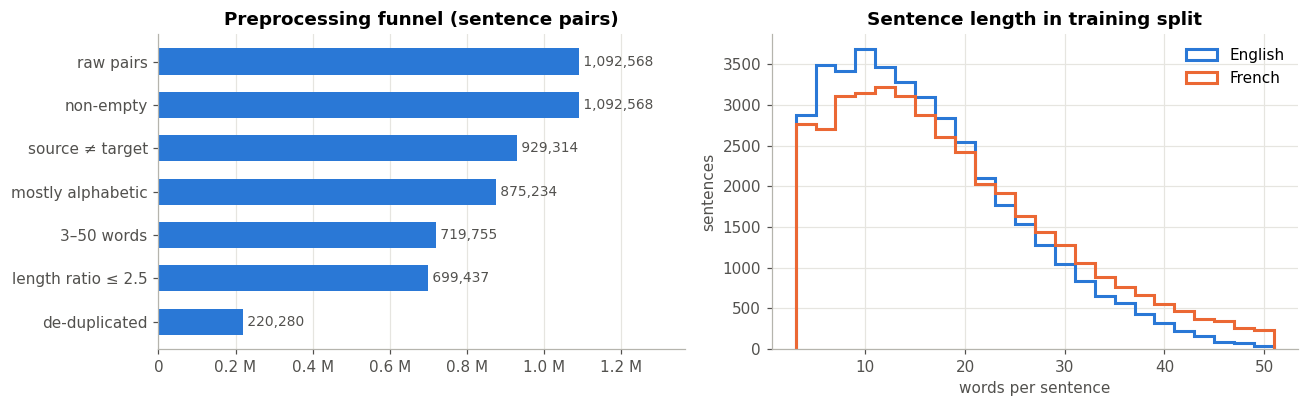

In [8]:
# Colours: blue = encoder–decoder / EN, orange = decoder-only / FR (fixed across all plots)
C_ENC, C_DEC, C_GRID, C_TXT = "#2a78d6", "#eb6834", "#e6e5e0", "#52514e"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
                     "axes.grid": True, "grid.color": C_GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
                     "xtick.color": C_TXT, "ytick.color": C_TXT, "axes.labelcolor": C_TXT, "figure.dpi": 110})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
ax.barh(funnel_df.step[::-1], funnel_df.pairs[::-1], color=C_ENC, height=0.6)
for y, v in enumerate(funnel_df.pairs[::-1]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=9, color=C_TXT)
ax.set_title("Preprocessing funnel (sentence pairs)"); ax.set_xlim(0, funnel_df.pairs.max() * 1.25); ax.grid(axis="y")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e6:.1f} M" if v else "0"))
ax = axes[1]
bins = np.arange(lo, hi + 2, 2)
ax.hist(train_df.en_w, bins=bins, histtype="step", linewidth=2, color=C_ENC, label="English")
ax.hist(train_df.fr_w, bins=bins, histtype="step", linewidth=2, color=C_DEC, label="French")
ax.set_title("Sentence length in training split"); ax.set_xlabel("words per sentence"); ax.set_ylabel("sentences")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/01_dataset.png", bbox_inches="tight"); plt.show()

## 2. Shared evaluation utilities
* **BLEU** and **chrF** with `sacrebleu` (corpus level, default 13a tokenisation, detokenised text).
* **Inference time** = wall-clock time to translate the whole test set (incl. tokenisation), and ms per sentence.
* **Training time** = wall-clock training / fine-tuning time (0 for prompting).
* **Parameters** = total parameters of the model used at inference + the number that were actually trained.
* Extra **reliability diagnostics** used in the responsible-AI section:
  *number fidelity* (share of digit sequences in the source that survive in the translation — critical for doses),
  *over-generation rate* (output > 2× reference length — a hallucination signal), *copy rate* (output = source)
  and *empty rate*.

All models use **greedy decoding with at most 128 new tokens** for the main comparison.

In [9]:
DIGITS = re.compile(r"\d+")

def score(hyps, refs):
    return (sacrebleu.corpus_bleu(hyps, [refs]).score, sacrebleu.corpus_chrf(hyps, [refs]).score)

def diagnostics(srcs, hyps, refs):
    kept, total = 0, 0
    for s, h in zip(srcs, hyps):
        need = Counter(DIGITS.findall(s))
        if need:
            have = Counter(DIGITS.findall(h))
            kept += sum(min(c, have[n]) for n, c in need.items()); total += sum(need.values())
    lens = [len(h.split()) / max(1, len(r.split())) for h, r in zip(hyps, refs)]
    return {"number_fidelity": 100 * kept / max(1, total),
            "overgen_rate": 100 * np.mean([l > 2 for l in lens]),
            "copy_rate": 100 * np.mean([h.strip().lower() == s.strip().lower() for s, h in zip(srcs, hyps)]),
            "empty_rate": 100 * np.mean([h.strip() == "" for h in hyps]),
            "len_ratio": float(np.mean(lens))}

def fertility(tokenize, srcs, refs):
    """Average number of sub-word tokens per whitespace word (lower = more efficient tokeniser)."""
    n_words_s, n_words_t = sum(len(s.split()) for s in srcs), sum(len(r.split()) for r in refs)
    return {"tok_per_word_en": sum(len(tokenize(s)) for s in srcs) / n_words_s,
            "tok_per_word_fr": sum(len(tokenize(r)) for r in refs) / n_words_t}

def record(key, hyps, **info):
    bleu, chrf = score(hyps, test_ref)
    STATE["metrics"][key] = {**info, "BLEU": bleu, "chrF": chrf, **diagnostics(test_src, hyps, test_ref)}
    with open(f"{TRANS_DIR}/{safe_name(key)}.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(h.replace("\n", " ") for h in hyps) + "\n")
    save_state()
    print(f"{key:32s} BLEU {bleu:6.2f} | chrF {chrf:6.2f} | infer {info.get('infer_time_s', 0):7.1f}s")

def evaluate_system(key, translate_fn, **info):
    """Greedy translation of the full test set with timing, then metrics + ethics probes."""
    set_seed(); sync(); t0 = time.perf_counter()
    hyps = translate_fn(test_src, 0.0)
    sync(); dt = time.perf_counter() - t0
    record(key, hyps, infer_time_s=dt, ms_per_sentence=1000 * dt / len(test_src), **info)
    STATE["probes"][key] = translate_fn([p for _, p in PROBES], 0.0)
    save_state()
    return hyps

EX_IDX = next(i for i, s in enumerate(test_src[:CFG["temp_n"]]) if 10 <= len(s.split()) <= 20) \
    if any(10 <= len(s.split()) <= 20 for s in test_src[:CFG["temp_n"]]) else 0

def temperature_sweep(key, translate_fn, greedy_hyps):
    """Sampling with temperature T (no top-k / top-p truncation) on the first `temp_n` test sentences."""
    n = CFG["temp_n"]; srcs, refs = test_src[:n], test_ref[:n]
    b, c = score(greedy_hyps[:n], refs)
    res = {"0.0": {"BLEU": b, "chrF": c, "example": greedy_hyps[EX_IDX]}}
    for t in CFG["temps"]:
        set_seed()
        hyps = translate_fn(srcs, t)
        b, c = score(hyps, refs)
        res[str(t)] = {"BLEU": b, "chrF": c, "example": hyps[EX_IDX], **diagnostics(srcs, hyps, refs)}
        print(f"  T={t:<4} BLEU {b:6.2f} | chrF {c:6.2f}")
    STATE["temperature"][key] = res
    save_state()

def batches_by_length(texts, batch_size):
    """Yield (indices, texts) batches sorted by length to minimise padding; caller restores order."""
    order = sorted(range(len(texts)), key=lambda i: len(texts[i]))
    for i in range(0, len(order), batch_size):
        idx = order[i:i + batch_size]
        yield idx, [texts[j] for j in idx]

# Hand-written probes for the responsible-AI analysis (Section 7)
PROBES = [
    ("gender", "The doctor told the nurse that she would arrive late."),
    ("gender", "The nurse said that he will check the patient's blood pressure."),
    ("gender", "My neighbour is a surgeon and a single parent."),
    ("gender", "The engineer asked the pharmacist about the side effects."),
    ("dosage", "Take 2.5 mg twice daily for 14 days; do not exceed 10 mg per day."),
    ("dosage", "Children under 6 years should receive half of the adult dose (0.5 ml)."),
    ("negation", "Do not stop taking this medicine without talking to your doctor."),
    ("sensitive", "Some patients have reported thoughts of suicide or self-harm while taking this medicine."),
    ("sensitive", "Tell your doctor if you are HIV-positive or if you are pregnant."),
    ("sensitive", "This medicine must not be used to treat addiction to alcohol or illegal drugs."),
    ("cultural", "If you are fasting during Ramadan, ask your doctor when to take your tablets."),
    ("cultural", "Do not take this medicine with grapefruit juice or herbal remedies such as St John's wort."),
    ("register", "If you feel dizzy, you should not drive."),
    ("short input", "Store below 25°C."),
    ("short input", "See section 4."),
]

## 3. Model 1 — Basic Transformer (encoder–decoder), trained from scratch

* **Tokenisation:** a joint English+French **SentencePiece BPE** vocabulary (8 k) learned on the training split only.
* **Architecture:** `nn.Transformer` — 4 encoder + 4 decoder layers, d_model 256, 4 heads, FFN 1024, pre-LayerNorm,
  sinusoidal positions, one embedding matrix shared by encoder, decoder and output projection.
* **Training:** label-smoothed (0.1) cross-entropy, Adam (β=0.9/0.98) with the inverse-square-root "Noam" warm-up
  schedule, mixed precision on GPU, length-bucketed batches, early stopping on validation loss.

In [10]:
PAD, UNK, BOS, EOS = 0, 1, 2, 3
spm_prefix = f"{CKPT_DIR}/spm_enfr"
if not os.path.exists(spm_prefix + ".model"):
    with open(f"{CKPT_DIR}/spm_train.txt", "w", encoding="utf-8") as f:
        f.write("\n".join(train_src + train_tgt) + "\n")
    spm.SentencePieceTrainer.train(
        input=f"{CKPT_DIR}/spm_train.txt", model_prefix=spm_prefix, vocab_size=CFG["spm_vocab"],
        model_type="bpe", character_coverage=1.0, pad_id=PAD, unk_id=UNK, bos_id=BOS, eos_id=EOS,
        hard_vocab_limit=False, minloglevel=2)
sp = spm.SentencePieceProcessor(model_file=spm_prefix + ".model")
print("SentencePiece vocab:", sp.get_piece_size())
print(sp.encode(test_src[0], out_type=str)[:20])


class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[: x.size(1)]


class Seq2SeqTransformer(nn.Module):
    def __init__(self, vocab, d_model, heads, layers, d_ff, dropout):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab, d_model, padding_idx=PAD)
        nn.init.normal_(self.emb.weight, mean=0.0, std=d_model ** -0.5)  # keeps tied output logits small at init
        with torch.no_grad():
            self.emb.weight[PAD].zero_()
        self.pos = PositionalEncoding(d_model)
        self.drop = nn.Dropout(dropout)
        self.transformer = nn.Transformer(d_model, heads, layers, layers, d_ff, dropout,
                                          batch_first=True, norm_first=True)
        self.out = nn.Linear(d_model, vocab, bias=False)
        self.out.weight = self.emb.weight  # weight tying

    def embed(self, ids):
        return self.drop(self.pos(self.emb(ids) * math.sqrt(self.d_model)))

    def encode(self, src):
        src_pad = src == PAD
        return self.transformer.encoder(self.embed(src), src_key_padding_mask=src_pad), src_pad

    def decode(self, tgt, memory, src_pad):
        T = tgt.size(1)
        causal = torch.triu(torch.ones(T, T, dtype=torch.bool, device=tgt.device), 1)
        h = self.transformer.decoder(self.embed(tgt), memory, tgt_mask=causal,
                                     tgt_key_padding_mask=tgt == PAD, memory_key_padding_mask=src_pad)
        return self.out(h)

    def forward(self, src, tgt_in):
        memory, src_pad = self.encode(src)
        return self.decode(tgt_in, memory, src_pad)


def tf_encode_src(texts):
    return [ids[: CFG["tf_max_len"] - 1] + [EOS] for ids in sp.encode(texts)]

def tf_encode_tgt(texts):
    return [[BOS] + ids[: CFG["tf_max_len"] - 2] + [EOS] for ids in sp.encode(texts)]

def pad_batch(seqs):
    out = torch.full((len(seqs), max(map(len, seqs))), PAD, dtype=torch.long)
    for i, s in enumerate(seqs):
        out[i, : len(s)] = torch.tensor(s)
    return out

def tf_batches(src_ids, tgt_ids, batch_size, shuffle):
    noise = (lambda: random.random() * 3) if shuffle else (lambda: 0)
    order = sorted(range(len(src_ids)), key=lambda i: len(src_ids[i]) + noise())
    batches = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
    if shuffle:
        random.shuffle(batches)
    for b in batches:
        yield pad_batch([src_ids[i] for i in b]).to(DEVICE), pad_batch([tgt_ids[i] for i in b]).to(DEVICE)


@torch.no_grad()
def tf_translate(model, texts, temperature=0.0):
    model.eval()
    outputs = [None] * len(texts)
    for idx, batch in batches_by_length(texts, CFG["eval_batch"]):
        src = pad_batch(tf_encode_src(batch)).to(DEVICE)
        memory, src_pad = model.encode(src)
        ys = torch.full((len(batch), 1), BOS, dtype=torch.long, device=DEVICE)
        done = torch.zeros(len(batch), dtype=torch.bool, device=DEVICE)
        for _ in range(CFG["max_new_tokens"]):
            logits = model.decode(ys, memory, src_pad)[:, -1, :].float()
            if temperature > 0:
                nxt = torch.multinomial(F.softmax(logits / temperature, -1), 1).squeeze(1)
            else:
                nxt = logits.argmax(-1)
            nxt = nxt.masked_fill(done, PAD)
            ys = torch.cat([ys, nxt.unsqueeze(1)], 1)
            done |= nxt == EOS
            if done.all():
                break
        for j, row in zip(idx, ys[:, 1:].tolist()):
            row = row[: row.index(EOS)] if EOS in row else row
            outputs[j] = sp.decode([t for t in row if t != PAD])
    return outputs

SentencePiece vocab: 8000
['▁Des', 'k', 't', 'op', '▁v', 'ide', 'oc', 'on', 'fer', 'enc', 'ing', '▁serv', 'ices', '▁will', '▁be', '▁ext', 'ended', '▁in', '▁2001', '▁to']


In [11]:
def run_transformer():
    key = "Transformer (scratch)"
    set_seed()
    tr_s, tr_t = tf_encode_src(train_src), tf_encode_tgt(train_tgt)
    va_s, va_t = tf_encode_src(val_src), tf_encode_tgt(val_tgt)
    model = Seq2SeqTransformer(sp.get_piece_size(), CFG["tf_d_model"], CFG["tf_heads"], CFG["tf_layers"],
                               CFG["tf_ff"], CFG["tf_dropout"]).to(DEVICE)
    n_params = count_params(model)
    print(f"Parameters: {n_params / 1e6:.2f} M")

    opt = torch.optim.Adam(model.parameters(), lr=1.0, betas=(0.9, 0.98), eps=1e-9)
    noam = lambda step: CFG["tf_d_model"] ** -0.5 * min((step + 1) ** -0.5, (step + 1) * CFG["tf_warmup"] ** -1.5)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, noam)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    V = sp.get_piece_size()

    def loss_on(src, tgt, smoothing):
        with torch.autocast(DEVICE.type, dtype=torch.bfloat16 if BF16 else torch.float16, enabled=use_amp):
            logits = model(src, tgt[:, :-1])
        return F.cross_entropy(logits.float().reshape(-1, V), tgt[:, 1:].reshape(-1),
                               ignore_index=PAD, label_smoothing=smoothing)

    curve, best, best_state, bad = [], float("inf"), None, 0
    sync(); t0 = time.perf_counter()
    for epoch in range(1, CFG["tf_epochs"] + 1):
        model.train(); tot, n = 0.0, 0
        for src, tgt in tf_batches(tr_s, tr_t, CFG["tf_batch"], shuffle=True):
            loss = loss_on(src, tgt, 0.1)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item(); n += 1
        model.eval(); vtot, vn = 0.0, 0
        with torch.no_grad():
            for src, tgt in tf_batches(va_s, va_t, CFG["tf_batch"], shuffle=False):
                vtot += loss_on(src, tgt, 0.0).item(); vn += 1
        tr_loss, va_loss = tot / n, vtot / vn
        curve.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss})
        print(f"epoch {epoch:2d} | train {tr_loss:.3f} | val {va_loss:.3f} | {time.perf_counter() - t0:6.0f}s")
        if va_loss < best - 1e-3:
            best, bad = va_loss, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= CFG["tf_patience"]:
                print("early stopping"); break
    sync(); train_time = time.perf_counter() - t0
    model.load_state_dict(best_state)
    torch.save(best_state, f"{CKPT_DIR}/transformer.pt")
    STATE["curves"][key] = curve

    fn = lambda texts, t: tf_translate(model, texts, t)
    hyps = evaluate_system(key, fn, family="Encoder–decoder", adaptation="Trained from scratch",
                           params_total=n_params, params_trainable=n_params, train_time_s=train_time,
                           **fertility(sp.encode, test_src, test_ref))
    temperature_sweep(key, fn, hyps)
    del model, opt; free_memory()

if not section_done("transformer"):
    run_transformer(); mark_done("transformer")

[skip] 'transformer' already finished — results loaded from results/state.json


## 4. Model 2 — mT5-small (encoder–decoder), full fine-tuning

mT5 is T5 pre-trained with a span-corruption objective on mC4 (101 languages). It has **not** been trained
on translation, so it must be fine-tuned. We use the task prefix `"translate English to French: "`, AdamW with
linear warm-up/decay, and fp32 (or bf16 on Ampere GPUs) — mT5 is known to produce NaNs in fp16.
Note that ~85 % of mT5-small's 300 M parameters are the 250 k-token multilingual embedding tables.

In [12]:
def lr_lambda(warmup, total):
    return lambda step: min((step + 1) / warmup, max(0.0, (total - step) / max(1, total - warmup)))

def hf_generation_config(model, temperature, eos_ids=None, pad_id=None):
    gc_ = copy.deepcopy(model.generation_config)
    gc_.max_new_tokens = CFG["max_new_tokens"]
    gc_.max_length = None
    gc_.num_beams = 1
    gc_.do_sample = temperature > 0
    gc_.temperature = temperature if temperature > 0 else 1.0
    gc_.top_k, gc_.top_p = 0, 1.0      # pure temperature sampling (no truncation) for a clean analysis
    if eos_ids is not None:
        gc_.eos_token_id = eos_ids
    if pad_id is not None:
        gc_.pad_token_id = pad_id
    return gc_

@torch.no_grad()
def mt5_translate(model, tok, texts, temperature=0.0):
    model.eval()
    outputs = [None] * len(texts)
    gcfg = hf_generation_config(model, temperature)
    for idx, batch in batches_by_length(texts, CFG["eval_batch"]):
        enc = tok([CFG["mt5_prefix"] + s for s in batch], max_length=CFG["mt5_max_len"], truncation=True,
                  padding=True, return_tensors="pt").to(DEVICE)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=BF16):
            out = model.generate(**enc, generation_config=gcfg)
        for j, text in zip(idx, tok.batch_decode(out, skip_special_tokens=True)):
            outputs[j] = re.sub(r"\s+", " ", re.sub(r"<extra_id_\d+>", "", text)).strip()  # drop sentinel tokens
    return outputs

def run_mt5():
    key = "mT5-small (fine-tuned)"
    set_seed()
    tok = AutoTokenizer.from_pretrained(CFG["mt5_name"])
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG["mt5_name"], dtype=torch.float32).to(DEVICE)
    n_params = count_params(model)
    print(f"Parameters: {n_params / 1e6:.1f} M")

    def collate(src, tgt):
        enc = tok([CFG["mt5_prefix"] + s for s in src], max_length=CFG["mt5_max_len"], truncation=True,
                  padding=True, return_tensors="pt")
        labels = tok(text_target=tgt, max_length=CFG["mt5_max_len"], truncation=True, padding=True,
                     return_tensors="pt").input_ids
        labels[labels == tok.pad_token_id] = -100
        enc["labels"] = labels
        return enc.to(DEVICE)

    bs = CFG["mt5_batch"]
    steps_per_epoch = math.ceil(len(train_src) / bs)
    total = steps_per_epoch * CFG["mt5_epochs"]
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["mt5_lr"], weight_decay=0.01)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda(max(1, int(0.05 * total)), total))

    curve = []
    sync(); t0 = time.perf_counter()
    for epoch in range(1, CFG["mt5_epochs"] + 1):
        model.train(); tot, n = 0.0, 0
        perm = np.random.permutation(len(train_src))
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            batch = collate([train_src[j] for j in b], [train_tgt[j] for j in b])
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=BF16):
                loss = model(**batch).loss
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            tot += loss.item(); n += 1
            if n % 500 == 0:
                print(f"  step {n}/{steps_per_epoch} loss {tot / n:.3f}")
        model.eval(); vtot, vn = 0.0, 0
        with torch.no_grad():
            for i in range(0, len(val_src), bs):
                with torch.autocast("cuda", dtype=torch.bfloat16, enabled=BF16):
                    vtot += model(**collate(val_src[i:i + bs], val_tgt[i:i + bs])).loss.item()
                vn += 1
        curve.append({"epoch": epoch, "train_loss": tot / n, "val_loss": vtot / vn})
        print(f"epoch {epoch} | train {tot / n:.3f} | val {vtot / vn:.3f} | {time.perf_counter() - t0:6.0f}s")
    sync(); train_time = time.perf_counter() - t0
    STATE["curves"][key] = curve

    fn = lambda texts, t: mt5_translate(model, tok, texts, t)
    hyps = evaluate_system(key, fn, family="Encoder–decoder", adaptation="Full fine-tuning",
                           params_total=n_params, params_trainable=n_params, train_time_s=train_time,
                           **fertility(lambda s: tok(s).input_ids, test_src, test_ref))
    temperature_sweep(key, fn, hyps)
    del model, opt; free_memory()

if not section_done("mt5"):
    run_mt5(); mark_done("mt5")

[skip] 'mt5' already finished — results loaded from results/state.json


## 5. Models 3 & 4 — LLaMA and Gemma (decoder-only)

Both are small instruction-tuned decoder-only LLMs. We use the **ungated** copies published by Unsloth, which
contain the same weights as `meta-llama/Llama-3.2-1B-Instruct` and `google/gemma-3-1b-it` but need no access request.

For each LLM we evaluate three adaptation methods:
1. **Zero-shot prompting** — an instruction in the model's own chat template.
2. **3-shot prompting (in-context learning)** — three fixed EMEA example pairs from the training split as previous chat turns.
3. **LoRA fine-tuning** — low-rank adapters (r = 16, α = 32) on all attention and MLP projections, trained for one epoch
   on 4 000 training pairs with the loss only on the French answer tokens. Adapters are merged before inference.

The source sentence is translated with the same greedy decoding and 128-token limit as the encoder–decoder models.

In [13]:
INSTRUCTION = ("Translate the following English sentence from a medical document into French. "
               "Reply with the French translation only.\n\nEnglish: {src}")

_shot_pool = [i for i, s in enumerate(train_src) if 8 <= len(s.split()) <= 20] or list(range(len(train_src)))
SHOTS = [(train_src[i], train_tgt[i]) for i in random.Random(SEED).sample(_shot_pool, CFG["n_shots"])]

def chat_messages(src, shots=()):
    msgs = []
    for s, t in shots:
        msgs += [{"role": "user", "content": INSTRUCTION.format(src=s)}, {"role": "assistant", "content": t}]
    return msgs + [{"role": "user", "content": INSTRUCTION.format(src=src)}]

def build_prompt(tok, src, shots=()):
    return tok.apply_chat_template(chat_messages(src, shots), add_generation_prompt=True, tokenize=False)

def clean_llm_output(text):
    lines = [l.strip() for l in text.strip().split("\n") if l.strip()]
    t = lines[0] if lines else ""
    t = re.sub(r"^(\*\*)?(French|Français|Translation|Traduction)( translation)?\s*:\s*(\*\*)?\s*", "", t, flags=re.I)
    if len(t) > 1 and t[0] in "\"«“'" and t[-1] in "\"»”'":
        t = t[1:-1].strip()
    return t

def load_llm(name):
    tok = AutoTokenizer.from_pretrained(name)
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).to(DEVICE)
    eos = set()
    for e in [model.generation_config.eos_token_id, tok.eos_token_id]:
        eos.update(e if isinstance(e, (list, tuple)) else [e] if e is not None else [])
    for t in ["<|eot_id|>", "<end_of_turn>", "<|im_end|>"]:
        tid = tok.convert_tokens_to_ids(t)
        if isinstance(tid, int) and tid != tok.unk_token_id:
            eos.add(tid)
    return tok, model, sorted(eos)

@torch.no_grad()
def llm_translate(model, tok, eos_ids, texts, temperature=0.0, shots=()):
    model.eval()
    tok.padding_side = "left"
    gcfg = hf_generation_config(model, temperature, eos_ids=eos_ids, pad_id=tok.pad_token_id)
    outputs = [None] * len(texts)
    for idx, batch in batches_by_length(texts, CFG["llm_eval_batch"]):
        enc = tok([build_prompt(tok, s, shots) for s in batch], return_tensors="pt", padding=True,
                  add_special_tokens=False).to(DEVICE)
        with torch.autocast("cuda", dtype=torch.bfloat16, enabled=BF16):
            out = model.generate(**enc, generation_config=gcfg)
        new_tokens = out[:, enc["input_ids"].shape[1]:]
        for j, text in zip(idx, tok.batch_decode(new_tokens, skip_special_tokens=True)):
            outputs[j] = clean_llm_output(text)
    return outputs

def lora_examples(tok, srcs, tgts):
    """Prompt tokens are masked with -100 so the loss is computed on the French answer only."""
    examples = []
    for s, t in zip(srcs, tgts):
        prompt = build_prompt(tok, s)
        full = tok.apply_chat_template(chat_messages(s) + [{"role": "assistant", "content": t}], tokenize=False)
        answer = full[len(prompt):] if full.startswith(prompt) else t + (tok.eos_token or "")
        p_ids = tok(prompt, add_special_tokens=False).input_ids
        a_ids = tok(answer, add_special_tokens=False).input_ids
        ids = (p_ids + a_ids)[: CFG["llm_max_len"]]
        labels = ([-100] * len(p_ids) + a_ids)[: CFG["llm_max_len"]]
        examples.append((ids, labels))
    return examples

def lora_finetune(model, tok, key):
    cfg = LoraConfig(r=CFG["lora_r"], lora_alpha=CFG["lora_alpha"], lora_dropout=CFG["lora_dropout"],
                     task_type="CAUSAL_LM",
                     target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
    model = get_peft_model(model, cfg)
    n_trainable = count_params(model, trainable_only=True)
    print(f"LoRA trainable parameters: {n_trainable / 1e6:.2f} M")

    data = lora_examples(tok, train_src[: CFG["llm_train"]], train_tgt[: CFG["llm_train"]])
    random.Random(SEED).shuffle(data)
    mb, accum = CFG["llm_batch"], CFG["llm_accum"]
    total = math.ceil(len(data) / (mb * accum))
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CFG["llm_lr"], weight_decay=0.0)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda(max(1, int(0.05 * total)), total))

    def collate(chunk):
        L = max(len(ids) for ids, _ in chunk)
        ids = torch.full((len(chunk), L), tok.pad_token_id, dtype=torch.long)
        lab = torch.full((len(chunk), L), -100, dtype=torch.long)
        att = torch.zeros((len(chunk), L), dtype=torch.long)
        for i, (x, y) in enumerate(chunk):        # right padding for training
            ids[i, : len(x)], lab[i, : len(y)], att[i, : len(x)] = torch.tensor(x), torch.tensor(y), 1
        return ids.to(DEVICE), att.to(DEVICE), lab.to(DEVICE)

    model.train(); losses = []
    sync(); t0 = time.perf_counter()
    for step in range(total):
        opt.zero_grad(set_to_none=True); step_loss = 0.0
        for k in range(accum):
            chunk = data[(step * accum + k) * mb: (step * accum + k + 1) * mb]
            if not chunk:
                continue
            ids, att, lab = collate(chunk)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=BF16):
                loss = model(input_ids=ids, attention_mask=att, labels=lab).loss / accum
            loss.backward(); step_loss += loss.item()
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
        opt.step(); sched.step(); losses.append(step_loss)
        if (step + 1) % 50 == 0 or step == total - 1:
            print(f"  step {step + 1}/{total} loss {np.mean(losses[-50:]):.3f} | {time.perf_counter() - t0:6.0f}s")
    sync(); train_time = time.perf_counter() - t0
    STATE["curves"][key] = [{"step": i + 1, "train_loss": l} for i, l in enumerate(losses)]
    model = model.merge_and_unload()
    model.eval()
    del opt
    return model, n_trainable, train_time

def run_llm(tag, name):
    set_seed()
    tok, model, eos_ids = load_llm(name)
    n_params = count_params(model)
    print(f"{tag}: {n_params / 1e6:.0f} M parameters | eos ids {eos_ids}")
    print("Example prompt:\n" + build_prompt(tok, test_src[0]))
    common = dict(family="Decoder-only", params_total=n_params,
                  **fertility(lambda s: tok(s, add_special_tokens=False).input_ids, test_src, test_ref))

    evaluate_system(f"{tag} (zero-shot)", lambda x, t: llm_translate(model, tok, eos_ids, x, t),
                    adaptation="Zero-shot prompting", params_trainable=0, train_time_s=0.0, **common)
    evaluate_system(f"{tag} (3-shot)", lambda x, t: llm_translate(model, tok, eos_ids, x, t, SHOTS),
                    adaptation="3-shot prompting", params_trainable=0, train_time_s=0.0, **common)

    key = f"{tag} (LoRA)"
    model, n_trainable, train_time = lora_finetune(model, tok, key)
    fn = lambda x, t: llm_translate(model, tok, eos_ids, x, t)
    hyps = evaluate_system(key, fn, adaptation="LoRA fine-tuning", params_trainable=n_trainable,
                           train_time_s=train_time, **common)
    temperature_sweep(key, fn, hyps)
    del model; free_memory()

In [14]:
if not section_done("llama"):
    run_llm("Llama-3.2-1B", CFG["llama_name"]); mark_done("llama")

config.json:   0%|          | 0.00/894 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/54.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/3.83k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Llama-3.2-1B: 1236 M parameters | eos ids [128001, 128008, 128009]
Example prompt:
<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 31 Oct 2026

<|eot_id|><|start_header_id|>user<|end_header_id|>

Translate the following English sentence from a medical document into French. Reply with the French translation only.

English: Desktop videoconferencing services will be extended in 2001 to facilitate conferences between the EMEA, European Commission and national competent authorities.<|eot_id|><|start_header_id|>assistant<|end_header_id|>


Llama-3.2-1B (zero-shot)         BLEU  20.83 | chrF  47.62 | infer   103.2s
Llama-3.2-1B (3-shot)            BLEU  24.62 | chrF  53.03 | infer   187.5s
LoRA trainable parameters: 11.27 M
  step 50/500 loss 1.248 |     98s
  step 100/500 loss 1.031 |    197s
  step 150/500 loss 1.048 |    294s
  step 200/500 loss 1.018 |    388s
  step 250/500 loss 1.017 |    485s
  step 300/500 loss 1.006 |   

In [15]:
if not section_done("gemma"):
    run_llm("Gemma-3-1B", CFG["gemma_name"]); mark_done("gemma")

config.json:   0%|          | 0.00/902 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/35.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/670 [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]

Gemma-3-1B: 1000 M parameters | eos ids [1, 106]
Example prompt:
<bos><start_of_turn>user
Translate the following English sentence from a medical document into French. Reply with the French translation only.

English: Desktop videoconferencing services will be extended in 2001 to facilitate conferences between the EMEA, European Commission and national competent authorities.<end_of_turn>
<start_of_turn>model

Gemma-3-1B (zero-shot)           BLEU  29.49 | chrF  56.07 | infer    83.4s
Gemma-3-1B (3-shot)              BLEU  30.96 | chrF  56.57 | infer   139.3s
LoRA trainable parameters: 13.05 M
  step 50/500 loss 1.452 |     72s
  step 100/500 loss 1.061 |    143s
  step 150/500 loss 1.054 |    214s
  step 200/500 loss 1.036 |    283s
  step 250/500 loss 1.043 |    353s
  step 300/500 loss 1.041 |    423s
  step 350/500 loss 0.932 |    496s
  step 400/500 loss 0.960 |    564s
  step 450/500 loss 0.989 |    636s
  step 500/500 loss 0.884 |    706s
Gemma-3-1B (LoRA)                BLEU  39

## 6. Evaluation and comparison
### 6.1 Main results table

In [16]:
ORDER = ["Transformer (scratch)", "mT5-small (fine-tuned)",
         "Llama-3.2-1B (zero-shot)", "Llama-3.2-1B (3-shot)", "Llama-3.2-1B (LoRA)",
         "Gemma-3-1B (zero-shot)", "Gemma-3-1B (3-shot)", "Gemma-3-1B (LoRA)"]
keys = [k for k in ORDER if k in STATE["metrics"]]
M = pd.DataFrame([{"System": k, **STATE["metrics"][k]} for k in keys]).set_index("System")
M["Params (M)"] = M.params_total / 1e6
M["Trainable (M)"] = M.params_trainable / 1e6
M["Train time (min)"] = M.train_time_s / 60
table = M[["family", "adaptation", "BLEU", "chrF", "Params (M)", "Trainable (M)", "Train time (min)",
           "infer_time_s", "ms_per_sentence"]].rename(columns={
    "family": "Architecture", "adaptation": "Adaptation", "infer_time_s": "Inference (s, test set)",
    "ms_per_sentence": "ms / sentence"}).round(2)
table.to_csv(f"{OUT_DIR}/metrics.csv")
table

,Architecture,Adaptation,BLEU,chrF,Params (M),Trainable (M),Train time (min),"Inference (s, test set)",ms / sentence
System,,,,,,,,,
Transformer (scratch),Encoder–decoder,Trained from scratch,37.14,60.31,9.42,9.42,7.02,6.50,13.00
mT5-small (fine-tuned),Encoder–decoder,Full fine-tuning,39.32,63.49,300.18,300.18,78.19,18.62,37.24
Llama-3.2-1B (zero-shot),Decoder-only,Zero-shot prompting,20.83,47.62,1235.81,0.00,0.00,103.18,206.36
Llama-3.2-1B (3-shot),Decoder-only,3-shot prompting,24.62,53.03,1235.81,0.00,0.00,187.53,375.06
Llama-3.2-1B (LoRA),Decoder-only,LoRA fine-tuning,36.92,61.55,1235.81,11.27,16.14,103.00,205.99
Gemma-3-1B (zero-shot),Decoder-only,Zero-shot prompting,29.49,56.07,999.89,0.00,0.00,83.43,166.86
Gemma-3-1B (3-shot),Decoder-only,3-shot prompting,30.96,56.57,999.89,0.00,0.00,139.25,278.50
Gemma-3-1B (LoRA),Decoder-only,LoRA fine-tuning,39.19,63.01,999.89,13.05,11.76,103.02,206.04


In [17]:
# Tokenisation and reliability diagnostics
diag = M[["tok_per_word_en", "tok_per_word_fr", "number_fidelity", "overgen_rate", "copy_rate", "empty_rate",
          "len_ratio"]].rename(columns={
    "tok_per_word_en": "Tokens/word EN", "tok_per_word_fr": "Tokens/word FR",
    "number_fidelity": "Number fidelity %", "overgen_rate": "Over-generation %", "copy_rate": "Copied source %",
    "empty_rate": "Empty %", "len_ratio": "Length ratio (hyp/ref)"}).round(2)
diag.to_csv(f"{OUT_DIR}/diagnostics.csv")
diag

,Tokens/word EN,Tokens/word FR,Number fidelity %,Over-generation %,Copied source %,Empty %,Length ratio (hyp/ref)
System,,,,,,,
Transformer (scratch),1.51,1.60,85.46,2.6,0.4,0.0,1.05
mT5-small (fine-tuned),1.72,2.03,90.54,2.2,1.0,0.0,1.05
Llama-3.2-1B (zero-shot),1.47,1.92,88.44,2.6,2.4,0.2,0.94
Llama-3.2-1B (3-shot),1.47,1.92,94.75,2.6,0.4,0.0,1.05
Llama-3.2-1B (LoRA),1.47,1.92,92.99,2.4,0.6,0.0,1.04
Gemma-3-1B (zero-shot),1.44,1.68,85.81,2.2,1.2,0.0,1.01
Gemma-3-1B (3-shot),1.44,1.68,88.44,1.6,0.6,0.0,0.98
Gemma-3-1B (LoRA),1.44,1.68,94.40,2.0,1.6,0.0,1.11


### 6.2 Plots

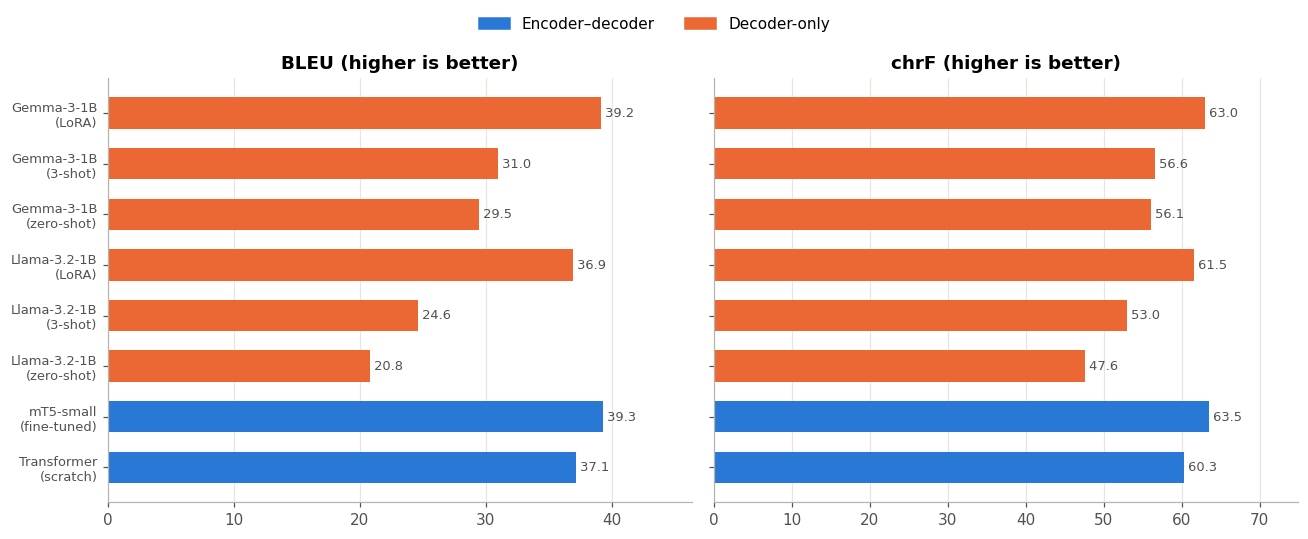

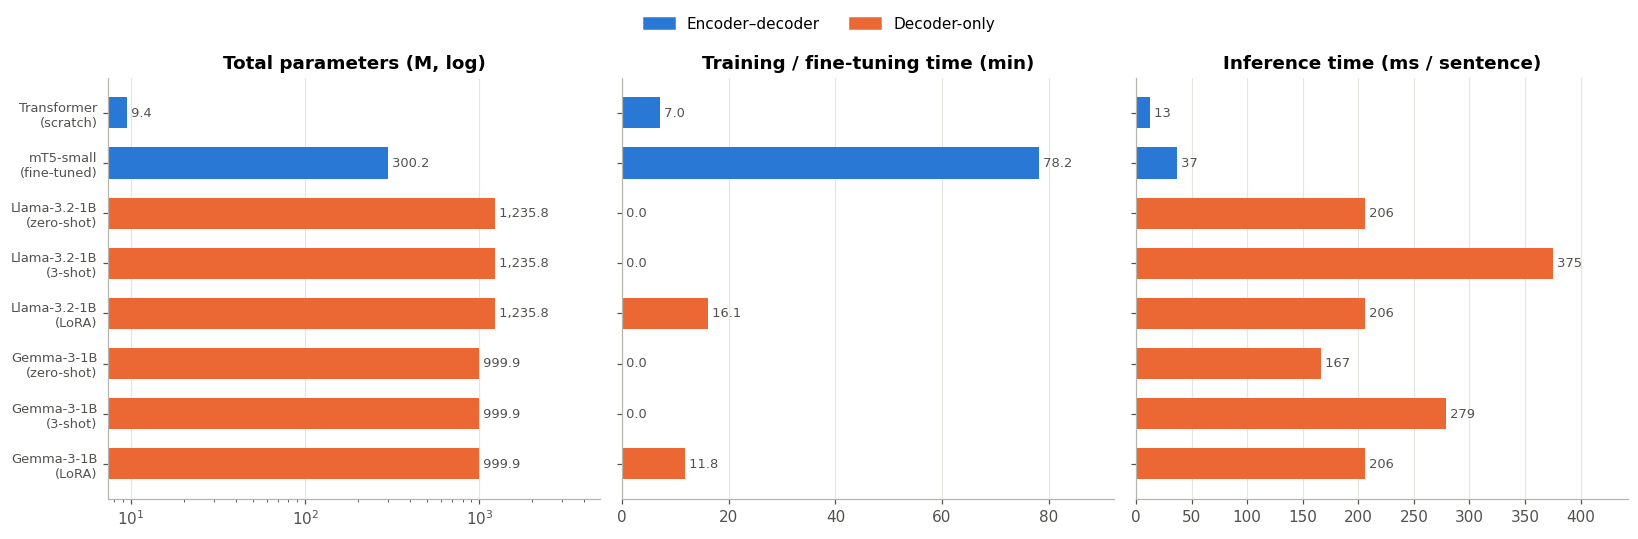

In [18]:
def family_color(k):
    return C_ENC if STATE["metrics"][k]["family"].startswith("Encoder") else C_DEC

def short(k):
    return k.replace(" (", "\n(")

def bar_panel(ax, values, title, fmt="{:.1f}", log=False):
    y = np.arange(len(keys))
    ax.barh(y, values, color=[family_color(k) for k in keys], height=0.62)
    ax.set_yticks(y, [short(k) for k in keys], fontsize=8.5); ax.invert_yaxis(); ax.grid(axis="y")
    if log:
        ax.set_xscale("log")
    for yi, v in zip(y, values):
        ax.text(v, yi, " " + fmt.format(v), va="center", fontsize=8.5, color=C_TXT)
    ax.set_xlim(right=(max(values) * (4 if log else 1.18)) if max(values) > 0 else 1)
    ax.set_title(title)

from matplotlib.patches import Patch
legend_items = [Patch(color=C_ENC, label="Encoder–decoder"), Patch(color=C_DEC, label="Decoder-only")]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
bar_panel(axes[0], M.BLEU.tolist(), "BLEU (higher is better)")
bar_panel(axes[1], M.chrF.tolist(), "chrF (higher is better)")
fig.legend(handles=legend_items, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.07))
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/02_quality.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
bar_panel(axes[0], M["Params (M)"].tolist(), "Total parameters (M, log)", "{:,.1f}", log=True)
bar_panel(axes[1], (M.train_time_s / 60).tolist(), "Training / fine-tuning time (min)")
bar_panel(axes[2], M.ms_per_sentence.tolist(), "Inference time (ms / sentence)", "{:.0f}")
fig.legend(handles=legend_items, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.07))
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/03_cost.png", bbox_inches="tight"); plt.show()

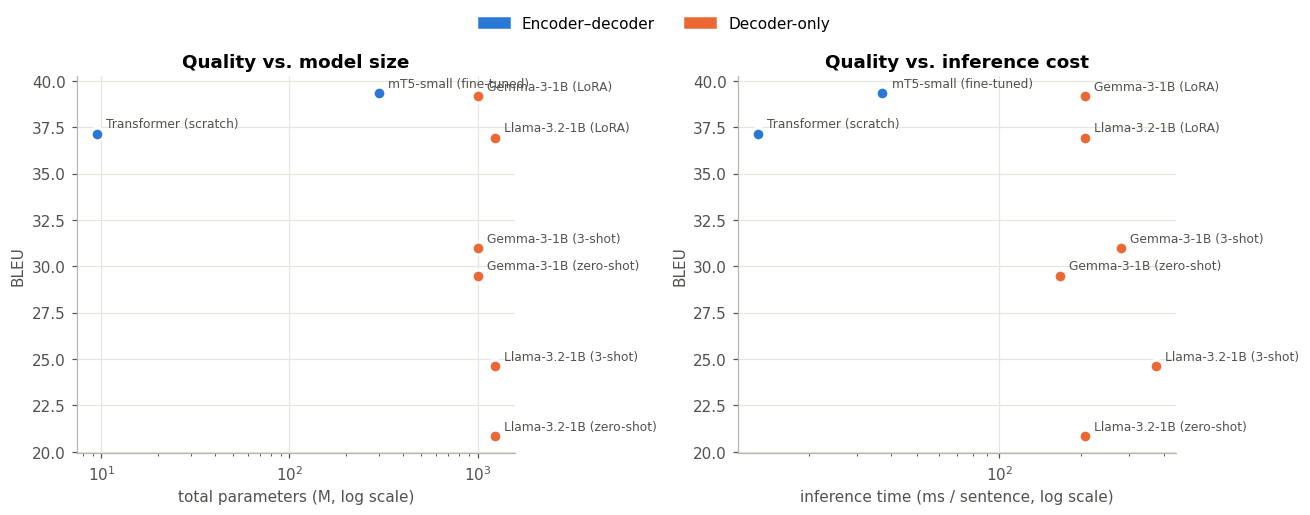

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, xcol, xlabel in [(axes[0], "Params (M)", "total parameters (M, log scale)"),
                         (axes[1], "ms_per_sentence", "inference time (ms / sentence, log scale)")]:
    for k in keys:
        ax.scatter(M.loc[k, xcol], M.loc[k, "BLEU"], s=70, color=family_color(k), edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(k, (M.loc[k, xcol], M.loc[k, "BLEU"]), textcoords="offset points", xytext=(6, 4),
                    fontsize=8, color=C_TXT)
    ax.set_xscale("log"); ax.set_xlabel(xlabel); ax.set_ylabel("BLEU")
axes[0].set_title("Quality vs. model size"); axes[1].set_title("Quality vs. inference cost")
fig.legend(handles=legend_items, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.07))
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/04_tradeoff.png", bbox_inches="tight"); plt.show()

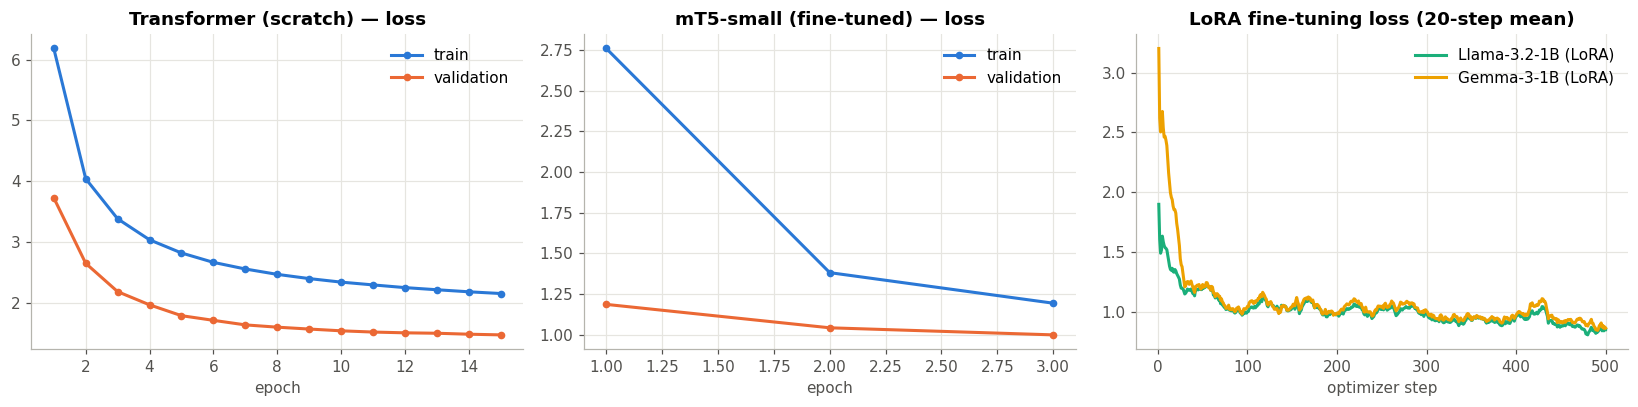

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for i, k in enumerate([k for k in ["Transformer (scratch)", "mT5-small (fine-tuned)"] if k in STATE["curves"]]):
    c = pd.DataFrame(STATE["curves"][k])
    axes[i].plot(c.epoch, c.train_loss, color=C_ENC, lw=2, marker="o", ms=4, label="train")
    axes[i].plot(c.epoch, c.val_loss, color=C_DEC, lw=2, marker="o", ms=4, label="validation")
    axes[i].set_title(f"{k} — loss"); axes[i].set_xlabel("epoch"); axes[i].legend(frameon=False)
for j, k in enumerate([k for k in ["Llama-3.2-1B (LoRA)", "Gemma-3-1B (LoRA)"] if k in STATE["curves"]]):
    c = pd.DataFrame(STATE["curves"][k])
    axes[2].plot(c.step, c.train_loss.rolling(20, min_periods=1).mean(), color=SERIES[2 + j], lw=2, label=k)
axes[2].set_title("LoRA fine-tuning loss (20-step mean)"); axes[2].set_xlabel("optimizer step"); axes[2].legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/05_training_curves.png", bbox_inches="tight"); plt.show()

### 6.3 Sampling-temperature analysis
Each fine-tuned model translates the first 200 test sentences with **pure temperature sampling**
(no top-k / top-p) at T ∈ {0.3, 0.7, 1.0, 1.5}; T = 0 is greedy decoding. Translation is a task with
(almost) one correct answer, so we expect quality to fall as T rises — the question is *how fast* for each model.

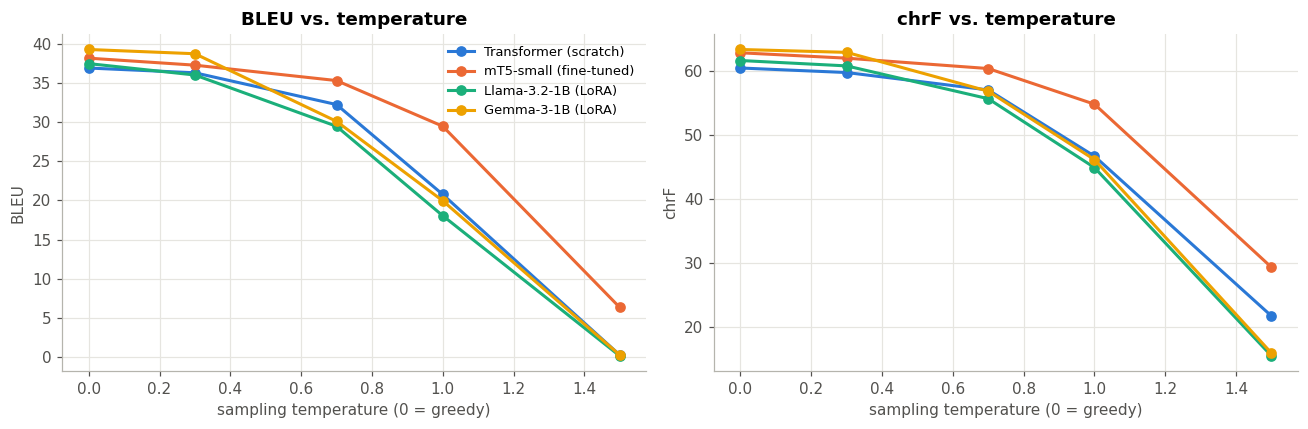

T,0.0,0.3,0.7,1.0,1.5
System,,,,,
Gemma-3-1B (LoRA),39.25,38.71,30.09,19.97,0.31
Llama-3.2-1B (LoRA),37.45,36.00,29.46,18.06,0.19
Transformer (scratch),36.89,36.28,32.23,20.77,0.30
mT5-small (fine-tuned),38.14,37.25,35.29,29.47,6.37


In [21]:
temp_keys = [k for k in ["Transformer (scratch)", "mT5-small (fine-tuned)", "Llama-3.2-1B (LoRA)", "Gemma-3-1B (LoRA)"]
             if k in STATE["temperature"]]
rows = [{"System": k, "T": float(t), "BLEU": v["BLEU"], "chrF": v["chrF"]}
        for k in temp_keys for t, v in STATE["temperature"][k].items()]
T_df = pd.DataFrame(rows)
T_df.to_csv(f"{OUT_DIR}/temperature.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for metric, ax in zip(["BLEU", "chrF"], axes):
    for i, k in enumerate(temp_keys):
        d = T_df[T_df.System == k].sort_values("T")
        ax.plot(d["T"], d[metric], color=SERIES[i], lw=2, marker="o", ms=6, label=k)
    ax.set_xlabel("sampling temperature (0 = greedy)"); ax.set_ylabel(metric); ax.set_title(f"{metric} vs. temperature")
axes[0].legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/06_temperature.png", bbox_inches="tight"); plt.show()

T_df.pivot(index="System", columns="T", values="BLEU").round(2)

In [22]:
print("Source   :", test_src[EX_IDX]); print("Reference:", test_ref[EX_IDX])
temp_examples = pd.DataFrame({k: {f"T={t}": v["example"] for t, v in STATE["temperature"][k].items()}
                              for k in temp_keys})
temp_examples

Source   : Desktop videoconferencing services will be extended in 2001 to facilitate conferences between the EMEA, European Commission and national competent authorities.
Reference: Les services de vidéoconférence de bureau seront étoffés en 2001 pour faciliter les conférences entre l'EMEA, la Commission européenne et les autorités nationales compétentes.


,Transformer (scratch),mT5-small (fine-tuned),Llama-3.2-1B (LoRA),Gemma-3-1B (LoRA)
T=0.0,Les boutêtements voconférant les services de c...,Les services de consultations de l’EMEA seront...,Les services de vidéoconférence sur ordinateur...,Les services de videoconférence sur bureau ser...
T=0.3,Des documents ad hoconencont des services de s...,"Les services de consultations de l’EMEA, de la...",Les services de vidéoconférence sur ordinateur...,Les services de videoconférence de bureau sero...
T=0.7,Des conférence vésoconférenti-exiguutatifs ser...,Le programme de consultation à usage externe s...,Les services de vidéoconférence en ligne seron...,Des services de videoconférence sur table sero...
T=1.0,La conférence vyrrolécon eachu les services se...,Les services de diffusion tablet devraient êtr...,Les services vidéo-conférences sur les dé oral...,Les services videoconférence fournis sur le bu...
T=1.5,Tout en ceauséesady donc grage le taux autoris...,Médicaments projetés de Mare65 sont sou 2.5 de...,Nic vidéoaccess happening from continuing vagu...,Una rechisable aves filmed Emirates喲 பிரissiqq...


## 7. Qualitative analysis & responsible AI
### 7.1 Sample translations from the test set

In [23]:
sample_idx = [i for i in range(len(test_src)) if DIGITS.search(test_src[i])][:4] + list(range(4))
hyp = {k: open(f"{TRANS_DIR}/{safe_name(k)}.txt", encoding="utf-8").read().split("\n") for k in keys}
lines = []
for i in dict.fromkeys(sample_idx):
    lines += [f"### Test sentence {i}", f"* **Source (EN):** {test_src[i]}", f"* **Reference (FR):** {test_ref[i]}"]
    lines += [f"* **{k}:** {hyp[k][i]}" for k in keys] + [""]
with open(f"{OUT_DIR}/sample_translations.md", "w", encoding="utf-8") as f:
    f.write("# Sample translations (test set, greedy decoding)\n\n" + "\n".join(lines))
print("\n".join(lines))

### Test sentence 0
* **Source (EN):** Desktop videoconferencing services will be extended in 2001 to facilitate conferences between the EMEA, European Commission and national competent authorities.
* **Reference (FR):** Les services de vidéoconférence de bureau seront étoffés en 2001 pour faciliter les conférences entre l'EMEA, la Commission européenne et les autorités nationales compétentes.
* **Transformer (scratch):** Les boutêtements voconférant les services de conférence au cours du traitement par l’EMEA, la Commission européenne et les autorités compétentes.
* **mT5-small (fine-tuned):** Les services de consultations de l’EMEA seront ouverts en 2001 afin de faciliter les événements entre l’EMEA, la Commission européenne et les autorités nationales compétentes.
* **Llama-3.2-1B (zero-shot):** Desktop vidéoconférences médicales seront étendues en 2001 pour faciliter les conférences entre le EMEA, la Commission européenne et les autorités compétentes nationales.
* **Llama-3.2-1B (3

### 7.2 Responsible-AI probe sentences
Hand-written inputs that target known MT failure modes: **gender bias** (French forces a grammatical gender that
English leaves unspecified), **dosage/number fidelity**, **negation**, **sensitive health information**
(suicide, HIV, pregnancy, addiction), **cultural context**, **formal register** (*vous* vs *tu*) and **very short
inputs** where chatty LLMs tend to add text that is not in the source.

In [24]:
probe_df = pd.DataFrame({"category": [c for c, _ in PROBES], "source": [p for _, p in PROBES],
                         **{k: STATE["probes"][k] for k in keys if k in STATE["probes"]}})
with open(f"{OUT_DIR}/ethics_probes.md", "w", encoding="utf-8") as f:
    f.write("# Responsible-AI probe translations\n\n")
    for i, (cat, src) in enumerate(PROBES):
        f.write(f"### [{cat}] {src}\n" + "".join(f"* **{k}:** {STATE['probes'][k][i]}\n"
                                                 for k in keys if k in STATE["probes"]) + "\n")
pd.set_option("display.max_colwidth", 120)
probe_df

,category,source,Transformer (scratch),mT5-small (fine-tuned),Llama-3.2-1B (zero-shot),Llama-3.2-1B (3-shot),Llama-3.2-1B (LoRA),Gemma-3-1B (zero-shot),Gemma-3-1B (3-shot),Gemma-3-1B (LoRA)
0,gender,The doctor told the nurse that she would arrive late.,Le médecin toléré le(e) qui serait arrive le late.,Le médecin a expliqué que la infirmière a été retardée.,The doctor a dit à la infirmière qu'elle arriverait tard.,Le médecin a dit à la infirmière qu'elle arriverait tard.,Le médecin lui a dit que la patiente arriverait tard.,La médecin a dit à la infirmière qu'elle arriverait en retard.,La médecin a dit à la infirmière qu’elle arriverait tard.,Le médecin a dit à la infirmière qu’elle arriverait en retard.
1,gender,The nurse said that he will check the patient's blood pressure.,Leinfirmier que l’aura la pression artérielle du patient.,Le infirmier a expliqué que l’examen de la pression artérielle du patient a vérifié la pression artérielle du patient.,Le médecin a dit à la patient que le médecin examinera le taux de pression sanguine.,L'infirmière a dit que le patient sera vérifié sur sa pression artérielle.,La nurse a déclaré qu’il lui faudra vérifier la pression artérielle du patient.,La réceptionniste a dit que le médecin vérifiera la tension artérielle du patient.,"Le/La soignant(e) va vérifier la tension artérielle du patient. (Note: Use ‘soignant’ if the nurse is male, ‘soignan...",La infirmière a dit qu’elle vérifierait la pression artérielle du patient.
2,gender,My neighbour is a surgeon and a single parent.,Myosbour est un endroit et un parent.,My partenaire est un chirurgien et un autre parent.,Neighbour est un chirurgien et père unique.,Mon voisin est un chirurgien et un père unique.,Mon voisin est un chirurgien et un seul père.,Mon voisin est un chirurgien et un parent seul.,Son voisin est un chirurgien et un parent seul.,Mon voisin est un chirurgien et un parent seul.
3,gender,The engineer asked the pharmacist about the side effects.,"Les effets indésirables sont les plus gêmes, comme étant susceptible d’entraîner les effets indésirables.",Le pharmacien a demandé le pharmacien concernant les effets indésirables.,The engineer a demandé au pharmacien sur les effets secondaires.,L'ingénieur demanda à l'assistant pharmacien des informations sur les effets secondaires.,L’ingénieur a demandé à la pharmacien des informations sur les effets indésirables.,Le technicien a demandé au pharmacien des effets secondaires.,Le technicien a demandé à la pharmacie des informations sur les effets secondaires.,L’ingénieur a demandé à la pharmacie des informations sur les effets indésirables.
4,dosage,Take 2.5 mg twice daily for 14 days; do not exceed 10 mg per day.,"Prendre 2,5 mg deux fois par jour pendant 14 jours; ne dépasse pas de 10 mg par jour.","Faites attention avec 2,5 mg deux fois par jour pendant 14 jours; ne dépassant pas 10 mg par jour.","2,5 mg deux fois par jour pendant 14 jours; ne dépasser 10 mg par jour.","Prendre 2,5 mg deux fois par jour pendant 14 jours; ne dépasser 10 mg par jour.","Prenez 2,5 mg deux fois par jour pendant 14 jours; ne dépasser 10 mg par jour.","Prendre 2,5 mg deux fois par jour pendant 14 jours; ne pas dépasser 10 mg par jour.","Prendre 2,5 mg deux fois par jour pendant 14 jours; ne pas dépasser 10 mg par jour.","Prenez 2,5 mg deux fois par jour pendant 14 jours; ne dépassez pas 10 mg par jour."
5,dosage,Children under 6 years should receive half of the adult dose (0.5 ml).,"Les enfants de moins de 6 ans doivent être traités par la dose (0,5 ml).","Enfants de moins de 6 ans doivent recevoir une demi-dose adulte (0,5 ml).","Enfants de moins de 6 ans devraient recevoir la moitié du dosage adulte (0,5 ml).","Enfants de moins de 6 ans devraient recevoir la dose d'adulte à la moitié (0,5 ml).","Les enfants de moins de 6 ans doivent recevoir la dose adulte (0,5 ml).","Les enfants de moins de 6 ans doivent recevoir la demi-dose de l’âge adulte (0,5 ml).",Les enfants de moins de 6 ans doivent recevoir la 

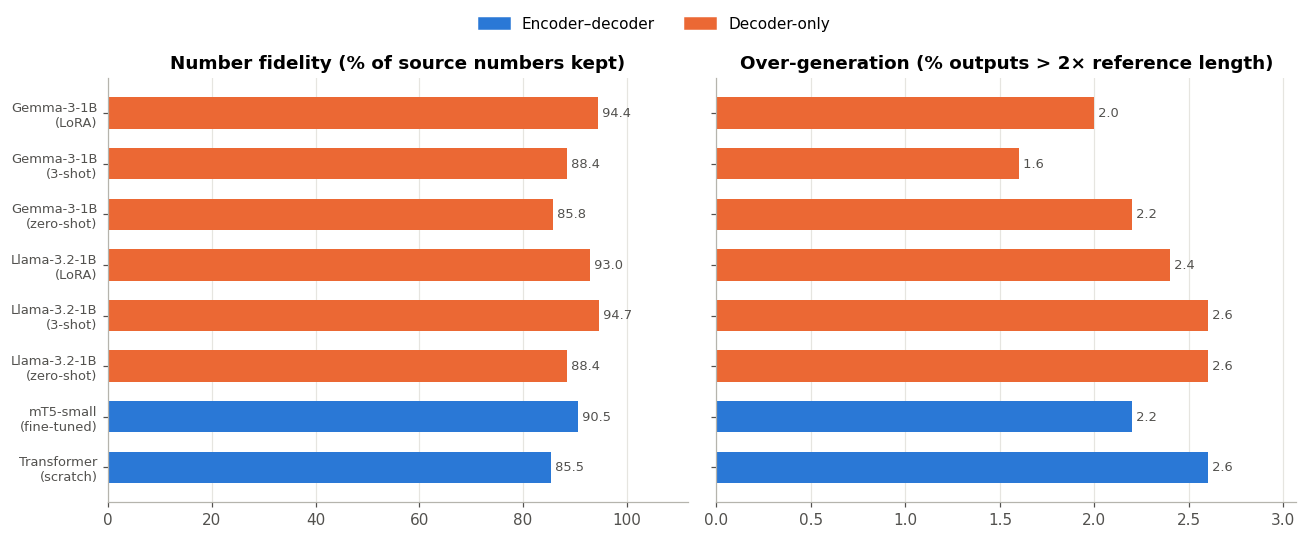

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
bar_panel(axes[0], M.number_fidelity.tolist(), "Number fidelity (% of source numbers kept)")
bar_panel(axes[1], M.overgen_rate.tolist(), "Over-generation (% outputs > 2× reference length)")
fig.legend(handles=legend_items, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.07))
plt.tight_layout(); plt.savefig(f"{PLOT_DIR}/07_reliability.png", bbox_inches="tight"); plt.show()

### 7.3 Discussion of responsible and ethical AI concerns

**Bias.** English often leaves gender unspecified (*the doctor*, *the nurse*, *my neighbour is a surgeon*) while French
must mark it (*le médecin / la médecin*, *l'infirmier / l'infirmière*). Systems trained on web or institutional text
tend to fall back on stereotypes (male doctor/surgeon/engineer, female nurse) unless the context forces otherwise.
The gender probes test this directly. EMEA itself is written in a neutral, generic-masculine style, so fine-tuned
models also inherit the generic masculine (*le patient*) even for female-specific contexts.

**Hallucinated information.** Decoder-only LLMs are trained to continue text and are tuned to be helpful, so with
prompting they may add explanations, notes or alternatives that are not in the source, especially for very short
inputs (*"See section 4."*). Encoder–decoder models hallucinate differently: under-trained models repeat phrases,
drop clauses or replace rare drug names with frequent ones. The *number-fidelity* and *over-generation* diagnostics
measure the most dangerous forms automatically.

**Cultural misrepresentation.** Medical register differs across cultures: French patient leaflets use the formal *vous*,
metric units and decimal commas (*2,5 mg*). Religious or cultural references (*Ramadan*, herbal remedies) may be
omitted, over-explained or translated literally. Training only on EU regulatory text also biases the system toward
European French and may not suit Canadian or African French-speaking readers.

**Inappropriate translation of sensitive content.** Suicide-risk warnings, HIV status, pregnancy and addiction require
precise, non-stigmatising wording. An instruction-tuned LLM may soften, refuse or add moralising text, and any
system can drop a negation (*"do not stop taking"* → *"stop taking"*), which inverts the medical meaning.

**Mitigations.**
1. *Human-in-the-loop:* medical translations must be post-edited and signed off by a qualified translator or clinician before use.
2. *Automatic safety checks* before release: number/unit/dosage consistency (as computed here), negation checks,
   a terminology glossary of drug names and length-ratio checks to flag likely hallucinations.
3. *Constrained decoding and fine-tuning* rather than open prompting, with greedy/low-temperature decoding
   (see the temperature analysis) so outputs are deterministic and auditable.
4. *Bias evaluation and mitigation:* gender-balanced test suites (e.g. WinoMT-style), gender-neutral or inclusive
   alternatives, or asking the user when gender is ambiguous; counterfactual data augmentation during fine-tuning.
5. *Quality estimation and uncertainty display:* show confidence scores / back-translations so users know when to distrust output.
6. *Transparency:* document data sources, licences, intended use and known limitations (model cards / datasheets),
   and clearly label machine-translated medical content.
7. *Privacy:* never send identifiable patient information to external translation APIs; prefer locally hosted models
   like the ones in this notebook.

Observations from the actual outputs of each model are summarised in the repository README.

## 8. Export results

In [26]:
summary = {"metrics": table.reset_index().to_dict(orient="records"),
           "diagnostics": diag.reset_index().to_dict(orient="records"),
           "temperature_bleu": T_df.pivot(index="System", columns="T", values="BLEU").round(2).reset_index().to_dict(orient="records"),
           "env": STATE["env"], "config": CFG}
with open(f"{OUT_DIR}/summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=1, ensure_ascii=False, default=str)
print(table.to_markdown())

# Bundle results/ and the data splits so they can be uploaded to GitHub
with zipfile.ZipFile("meditrans_fr_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, fnames in os.walk(OUT_DIR):
        for fn in fnames:
            z.write(os.path.join(root, fn))
    for split in ("train", "val", "test"):
        z.write(f"{DATA_DIR}/{split}.tsv")
print("Saved meditrans_fr_results.zip")
if IN_COLAB:
    from google.colab import files
    files.download("meditrans_fr_results.zip")

| System                   | Architecture    | Adaptation           |   BLEU |   chrF |   Params (M) |   Trainable (M) |   Train time (min) |   Inference (s, test set) |   ms / sentence |
|:-------------------------|:----------------|:---------------------|-------:|-------:|-------------:|----------------:|-------------------:|--------------------------:|----------------:|
| Transformer (scratch)    | Encoder–decoder | Trained from scratch |  37.14 |  60.31 |         9.42 |            9.42 |               7.02 |                      6.5  |           13    |
| mT5-small (fine-tuned)   | Encoder–decoder | Full fine-tuning     |  39.32 |  63.49 |       300.18 |          300.18 |              78.19 |                     18.62 |           37.24 |
| Llama-3.2-1B (zero-shot) | Decoder-only    | Zero-shot prompting  |  20.83 |  47.62 |      1235.81 |            0    |               0    |                    103.18 |          206.36 |
| Llama-3.2-1B (3-shot)    | Decoder-only    | 3-shot prompt